# 00. Entendimiento y Preparación de los Datos
**Materia:** INF432 - Sistemas para el Soporte a la Toma de Decisiones  
**Proyecto:** Minería de datos para decisiones comerciales - RetailMarket Santa Cruz  
**Autor (Integrante 1):** Diogo Nicolas Rodríguez Gómez (Reg. 221045686)  

Este notebook realiza la carga inicial, auditoría de calidad, limpieza, ingeniería de variables derivadas, codificación, estandarización y división 70/30 sobre el conjunto de datos crudo para generar los datos procesados reproducibles.

### Fuente, licencia y diccionario de datos

**Fuente.** Patel, A. (2021). *Customer Personality Analysis* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

**Licencia.** CC0: Public Domain.

**Origen y naturaleza de los datos.** El archivo proviene del reto de contratación *iFood CRM Data Analyst Case*, cuyo enunciado aclara que los datos son una muestra simulada de clientes y campañas. Sirven para practicar el proceso, pero sus resultados no describen a una empresa real ni a clientes de Santa Cruz. No contienen nombres, documentos ni teléfonos; `ID` se elimina durante la limpieza.

| Variable | Descripción |
|---|---|
| `ID` | Identificador del cliente |
| `Year_Birth` | Año de nacimiento |
| `Education` | Nivel educativo |
| `Marital_Status` | Estado civil |
| `Income` | Ingreso anual del hogar |
| `Kidhome` / `Teenhome` | Niños / adolescentes en el hogar |
| `Dt_Customer` | Fecha de registro del cliente |
| `Recency` | Días desde la última compra |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | Gasto por categoría en los últimos 2 años |
| `NumDealsPurchases` | Compras con descuento |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | Compras por web, catálogo y tienda |
| `NumWebVisitsMonth` | Visitas al sitio web en el último mes |
| `AcceptedCmp1` a `AcceptedCmp5` | 1 si aceptó la oferta de esa campaña, 0 si no |
| `Complain` | 1 si presentó una queja en los últimos 2 años |
| `Z_CostContact` / `Z_Revenue` | Costo por contacto (3 unidades) / ingreso por aceptación (11 unidades). Coinciden con el costo total de 6720 e ingreso de 3674 del enunciado del reto |
| `Response` | **Variable de clase:** 1 si aceptó la oferta de la última campaña |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Fijar semilla global obligatoria
SEMILLA = 1
np.random.seed(SEMILLA)

# Crear carpetas si no existen
os.makedirs('data/raw', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
os.makedirs('reports/figures', exist_ok=True)

### 3.1 Carga del conjunto de datos crudo
Cargamos el archivo original desde la ruta relativa `data/raw/marketing_campaign.csv`. Este dataset utiliza tabulaciones (`\t`) como separador.

In [2]:
# Cargar datos crudos
df_raw = pd.read_csv('data/raw/marketing_campaign.csv', sep='\t')
print("Dimensiones originales (filas, columnas):", df_raw.shape)
df_raw.head()

Dimensiones originales (filas, columnas): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


### 3.2 Diagnóstico de Calidad de Datos
Auditamos valores faltantes, registros duplicados y tipos de datos por columna.

In [3]:
# Información general y tipos
df_raw.info()

# Revisar valores nulos
nulos = df_raw.isna().sum()
print("\n--- Valores faltantes por columna ---")
print(nulos[nulos > 0])

# Revisar duplicados exactos
duplicados = df_raw.duplicated().sum()
# El ID oculta las copias: cada una tiene un ID distinto
duplicados_sin_id = df_raw.drop(columns=['ID']).duplicated().sum()
print(f"\nRegistros duplicados con ID: {duplicados}")
print(f"Registros duplicados sin considerar ID: {duplicados_sin_id}")

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

### 3.2.1 Estadística descriptiva y valores atípicos

Resumimos las variables numéricas y contamos los posibles atípicos con la regla del rango intercuartílico (valores a más de 1,5 RIC de los cuartiles). Esta regla solo señala casos para revisar: no significa que sean errores.

In [4]:
variables_revision = [
    'Year_Birth', 'Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
    'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases',
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth'
]

display(df_raw[variables_revision].describe().T.round(2))

q1 = df_raw[variables_revision].quantile(0.25)
q3 = df_raw[variables_revision].quantile(0.75)
ric = q3 - q1
fuera = (df_raw[variables_revision] < q1 - 1.5 * ric) | (df_raw[variables_revision] > q3 + 1.5 * ric)

tabla_atipicos = pd.DataFrame({
    'Posibles atípicos': fuera.sum(),
    'Porcentaje (%)': (fuera.mean() * 100).round(2),
    'Mínimo': df_raw[variables_revision].min(),
    'Máximo': df_raw[variables_revision].max()
})
display(tabla_atipicos)

,count,mean,std,min,25%,50%,75%,max
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0
MntSweetProducts,2240.0,27.06,41.28,0.0,1.00,8.0,33.00,263.0
MntGoldProds,2240.0,44.02,52.17,0.0,9.00,24.0,56.00,362.0
NumDealsPurchases,2240.0,2.33,1.93,0.0,1.00,2.0,3.00,15.0


,Posibles atípicos,Porcentaje (%),Mínimo,Máximo
Year_Birth,3,0.13,1893.0,1996.0
Income,8,0.36,1730.0,666666.0
Recency,0,0.00,0.0,99.0
MntWines,35,1.56,0.0,1493.0
MntFruits,227,10.13,0.0,199.0
MntMeatProducts,175,7.81,0.0,1725.0
MntFishProducts,223,9.96,0.0,259.0
MntSweetProducts,248,11.07,0.0,263.0
MntGoldProds,207,9.24,0.0,362.0
NumDealsPurchases,86,3.84,0.0,15.0


**Lectura de los atípicos.** Solo se tratan como errores los valores imposibles o sin sentido: los años de nacimiento 1893, 1899 y 1900, y un ingreso de 666 666. Se eliminan en la sección 4.

Los gastos y compras elevados se conservan, porque son comportamientos comerciales posibles y aportan información. La asimetría que producen se considera en cada área.

### 4. Preparación de los Datos
1. **Faltantes en Income:** Se imputan con la mediana del ingreso calculada **solo con entrenamiento**, después de dividir (al ser solo 24 casos de 2.240, ~1%, la imputación por mediana preserva la muestra). Ver la sección 4.3.
2. **Eliminación de columnas no informativas:** `ID` (identificador), `Z_CostContact` y `Z_Revenue` (constantes con varianza 0, por lo que no aportan a los modelos). Sus valores sí se usan en `02_Area_A1_Marketing.ipynb` para el análisis de costos.
3. **Ingeniería de variables derivadas:**
   - `Age`: 2014 - `Year_Birth`. Se usa 2014 porque los registros de clientes llegan hasta ese año: así la edad corresponde al mismo momento que las compras.
   - `Total_Spent`: Suma de gastos en vinos, frutas, carnes, pescados, dulces y oro (`MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds`).
   - `Total_Purchases`: Suma de compras por web, catálogo y tienda física (`NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`).
   - `Children`: Suma de niños y adolescentes en casa (`Kidhome` + `Teenhome`).
   - `Family_Size`: Tamaño estimado del hogar según estado civil (`Marital_Status`) y cantidad de hijos.
   - `Customer_Days`: Días transcurridos como cliente desde `Dt_Customer`.
4. **Filtro de valores atípicos severos:** Clientes con `Age > 100` o ingresos anómalos extremos (`Income > 200000`).
5. **Eliminación de filas repetidas:** Después de quitar `ID`, 204 filas tienen los mismos predictores que otra. Se conserva la primera aparición. Esto debe hacerse **antes de dividir**: una copia en entrenamiento y otra en prueba es fuga de datos, porque el modelo se evaluaría con casos que ya vio. En 19 de esas filas solo difiere `Response`; también se conserva la primera, ya que el dato no permite saber cuál es la correcta.

In [5]:
df = df_raw.copy()

# 1. Los nulos de Income se imputan después de dividir (sección 4.3)

# 2. Filtrar atípicos lógicos
# Año de referencia de los datos: 2014, último año de registro de clientes
df['Age'] = 2014 - df['Year_Birth']
df = df[df['Age'] <= 100]
# Se conservan los clientes sin ingreso: solo se excluyen los valores extremos
df = df[df['Income'].isna() | (df['Income'] < 200000)]

# 3. Variables derivadas
df['Total_Spent'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + 
                     df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

df['Total_Purchases'] = (df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases'])

df['Children'] = df['Kidhome'] + df['Teenhome']

# Simplificar estado civil
mapeo_marital = {
    'Married': 2, 'Together': 2, 
    'Single': 1, 'Divorced': 1, 'Widow': 1, 'Alone': 1, 'Absurd': 1, 'YOLO': 1
}
df['Family_Size'] = df['Marital_Status'].map(mapeo_marital) + df['Children']

# Antigüedad en días como cliente (asumiendo fecha de corte)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')
fecha_referencia = df['Dt_Customer'].max()
df['Customer_Days'] = (fecha_referencia - df['Dt_Customer']).dt.days

# Simplificar Educación (Ordinal/Numérica)
# Basic: 0, 2n Cycle: 1, Graduation: 2, Master: 3, PhD: 4
mapeo_edu = {'Basic': 0, '2n Cycle': 1, 'Graduation': 2, 'Master': 3, 'PhD': 4}
df['Education_Level'] = df['Education'].map(mapeo_edu)

# 4. Eliminar columnas innecesarias o constantes
columnas_descartar = ['ID', 'Year_Birth', 'Dt_Customer', 'Education', 'Marital_Status', 'Z_CostContact', 'Z_Revenue']
df = df.drop(columns=columnas_descartar)

# 5. Eliminar filas repetidas antes de dividir, para evitar fuga de datos
columnas_predictoras = df.columns.drop('Response')
filas_antes = len(df)
df = df.drop_duplicates(subset=columnas_predictoras, keep='first').reset_index(drop=True)
print(f"Filas repetidas eliminadas: {filas_antes - len(df)}")

print("Dimensiones tras limpieza:", df.shape)

Filas repetidas eliminadas: 204
Dimensiones tras limpieza: (2032, 29)


### 3.3 Visualización y Distribución
Generamos el gráfico de barras de la variable objetivo supervisada (`Response`) y la matriz de correlación entre los gastos y la respuesta del cliente.

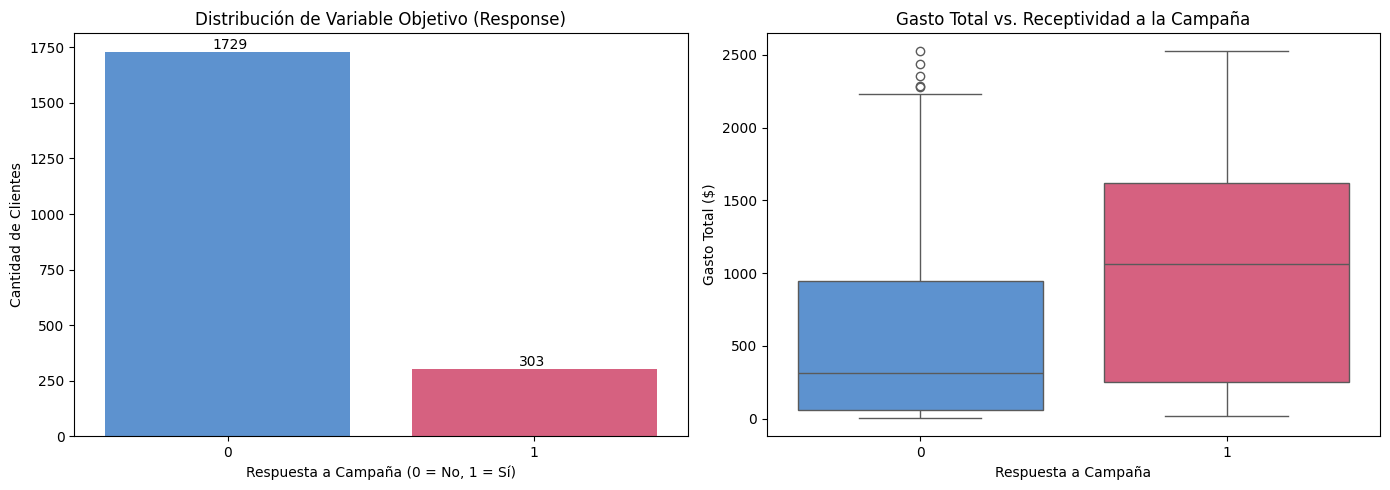

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de la clase Response
sns.countplot(x='Response', hue='Response', data=df, ax=axes[0], palette=['#4A90E2', '#E94E77'], legend=False)
axes[0].set_title('Distribución de Variable Objetivo (Response)')
axes[0].set_xlabel('Respuesta a Campaña (0 = No, 1 = Sí)')
axes[0].set_ylabel('Cantidad de Clientes')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 15))

# Distribución del gasto total según respuesta
sns.boxplot(x='Response', y='Total_Spent', hue='Response', data=df, ax=axes[1], palette=['#4A90E2', '#E94E77'], legend=False)
axes[1].set_title('Gasto Total vs. Receptividad a la Campaña')
axes[1].set_xlabel('Respuesta a Campaña')
axes[1].set_ylabel('Gasto Total ($)')

plt.tight_layout()
plt.savefig('reports/figures/exploracion_inicial.png', dpi=300)
plt.show()

### 4.3 Partición 70/30 y Estandarización (`StandardScaler`)
Aplicamos la **Regla de Oro** del curso: la división entrenamiento/prueba se realiza primero con `random_state=1` y `test_size=0.30`. La mediana para imputar `Income` se calcula solo con entrenamiento y se aplica a ambos conjuntos. El escalador `StandardScaler` se ajusta (`fit`) únicamente sobre los datos de entrenamiento y transforma (`transform`) ambos conjuntos para evitar la fuga de datos (*data leakage*).

In [7]:
# Separar Atributos (X) y Clase (y)
X = df.drop(columns=['Response'])
y = df['Response']

# División 70/30 estratificada para mantener la proporción de la clase
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEMILLA, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} casos")
print(f"Prueba: {X_test.shape[0]} casos")
print(f"Proporción de clase 1 en Train: {y_train.mean():.2%}")
print(f"Proporción de clase 1 en Test: {y_test.mean():.2%}")

# Imputar Income con la mediana de entrenamiento: prueba no influye en ese valor
mediana_income = X_train['Income'].median()
print(f"\nMediana de Income en entrenamiento: {mediana_income:.1f}")
print(f"Faltantes imputados: {X_train['Income'].isna().sum()} en Train y {X_test['Income'].isna().sum()} en Test")

X_train = X_train.assign(Income=X_train['Income'].fillna(mediana_income))
X_test = X_test.assign(Income=X_test['Income'].fillna(mediana_income))

# La base descriptiva usa el mismo valor, para que todos los notebooks coincidan
df['Income'] = df['Income'].fillna(mediana_income)

# Estandarización con StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# Guardar datos preparados limpios (sin escalar y escalados) para los demás notebooks
df.to_csv('data/processed/data_limpia_original.csv', index=False)

# Guardar train y test listos para modelado
train_processed = X_train_scaled.copy()
train_processed['Response'] = y_train
train_processed.to_csv('data/processed/train_scaled.csv', index=False)

test_processed = X_test_scaled.copy()
test_processed['Response'] = y_test
test_processed.to_csv('data/processed/test_scaled.csv', index=False)

print("\n¡Datos exportados con éxito a 'data/processed/'!")

Entrenamiento: 1422 casos
Prueba: 610 casos
Proporción de clase 1 en Train: 14.91%
Proporción de clase 1 en Test: 14.92%

Mediana de Income en entrenamiento: 52074.0
Faltantes imputados: 17 en Train y 7 en Test

¡Datos exportados con éxito a 'data/processed/'!
